# Guardar y limpiar fichero 

## 1. Guardar fichero sin limpiar en /datos/raw

In [2]:
import requests
from pathlib import Path
 
URL = "https://raw.githubusercontent.com/bigdatawirtz/datasets/main/datasets/meteo_alvedro_2021_2025.csv"
resposta = requests.get(URL, timeout=30)
resposta.raise_for_status()
destino = Path("../datos/raw/meteo_alvedro_2021_2025.csv")
destino.write_bytes(resposta.content)

81825

## 2- Proceso de análisis por pasos

***1- Analizar bytes , primeras y últimas líneas***

In [ ]:
print(destino.read_bytes()[:120])

b'Servizo de exportaci\xf3n de datos meteorol\xf3xicos\nEstaci\xf3n: A Coru\xf1a / Alvedro (aeroporto) \xb7 Indicativo: 08002\nLatitude: 43'


In [4]:
with open(destino, encoding="latin-1") as f:
    for _ in range(8):
        print(f.readline().rstrip())

Servizo de exportación de datos meteorolóxicos
Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002
Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m
Período: 01/01/2021 - 31/12/2025
Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins didácticos.

Data;Temp. media (ºC);Temp. mínima (ºC);Temp. máxima (ºC);Humidade relativa (%);Precipitación (mm);Vento medio (km/h);Presión (hPa)
2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7


In [11]:
with open(destino, encoding="latin-1") as f:
    for i in f.readlines()[-5:]:
        print(i)

2025-06-10;20,8;15,6;27,6;80;Ip;6,2;1.015,7

2021-04-16;10,0;3,6;17,2;56;0,0;11,7;1.020,1

2022-05-21;19,9;10,9;24,7;81;2,9;5,8;1.015,6

2025-10-12;17,6;9,9;24,9;74;0,0;5,8;1.018,8

17/08/2023;20,1;14,2;26,7;77;0,5;9,3;1.014,7



- Identificar a codificación, as liñas que non son datos, o separador, o separador decimal e os códigos que indican valor ausente

    - Codificación: Detectamos la codificación exacta debido a estos caracteres : \xf3n \xb7 . Los cuales nos muestran que se presenta un  ISO-8859-1 (Latin-1) en los bytes
    - Lineas que no son datos: Nos muestran que las primeras 6 líneas son datos sin interés (skiprows) debido a que nos muestran información del archivo y espacios.
    - Separadores :  Vemos como el separador principal entre datos es ';' , el decimal es ',' y los códigos que representan valores ausentes se correspondena un separador sin contenido delante, es decir , vacío ';;' o "" .


***2-Comprobar tipos de columnas***

- Para comprobar los tipos de columnas primero crearemos el dataframe encargado de contener los datos de nuestro csv , configurandolo según las características anteriormente analizadas.

In [32]:
import pandas as pd

tiempo = pd.read_csv(
    destino,
    encoding="latin-1",
    skiprows=6,
    sep=";",
    decimal=",",
    na_values=[""],
)
tiempo.head()

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,"12,2",11.0,"1.015,7"
1,2021-01-02,5.5,3.1,9.7,91,"9,8",6.4,"1.019,8"
2,2021-01-03,5.6,3.0,8.4,92,"12,4",8.5,"1.018,9"
3,2021-01-04,3.6,-0.3,6.8,92,"4,7",7.8,"1.015,4"
4,2021-01-05,2.8,-1.5,9.4,94,"1,2",6.2,"1.014,6"


In [82]:
tiempo.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Data                   1812 non-null   str    
 1   Temp. media (ºC)       1803 non-null   float64
 2   Temp. mínima (ºC)      1806 non-null   float64
 3   Temp. máxima (ºC)      1803 non-null   float64
 4   Humidade relativa (%)  1812 non-null   int64  
 5   Precipitación (mm)     1804 non-null   str    
 6   Vento medio (km/h)     1812 non-null   float64
 7   Presión (hPa)          1811 non-null   str    
dtypes: float64(4), int64(1), str(3)
memory usage: 113.4 KB


- Al comprobar que la columna 'Data' se trata de un str procedemos a su conversión a datetime. 
    - Debido a que tenemos diferentes formatos de fechas (2023-06-30 , 01/07/2023) utilizaremos "mixed" en la etiqueta format para automatizarlo y tratar cada fecha invidualmente.


- Descubrimos que el tipo de algunas columnas que contienen datos aparentemente int o float son str con el siguiente razonamiento:

    - Precipitaciones Ip (precipitación inapreciable) :  Guardamos en una lista por comprensión si hay datos tipo str en x columna los cuales no tengan el separador numérico ,así descartamos un error a la hora de crear el dataframe frente la posibilidad de que se hayan insertado datos erróneas en las colmnas en el documento csv de github, como segunda opción podremos realizar un print de la columna.

    - Presión : Aparentemente en esta columna no podríamos utilizar los anteriores métodos , así que recurrimos a mostrar si existen caracteres ocultos en las columnas que no podemos ver a simple vista con la función repr() la cual nos muestra que para pasar de línea añaden un \n al final de cada línea.



In [ ]:
with open(destino, encoding="latin-1") as f:
    for _ in range(8):
        print(repr(f.readline()))



#realizamos la conversión de presion a float
# Reemplaza la coma por punto y convierte a float
# tiempo['Presión (hPa)'] = tiempo['Presión (hPa)'].str.replace(',', '.').astype(float)
# tiempo.head()

'Servizo de exportación de datos meteorolóxicos\n'
'Estación: A Coruña / Alvedro (aeroporto) · Indicativo: 08002\n'
'Latitude: 43,3000 · Lonxitude: -8,3833 · Altitude: 97 m\n'
'Período: 01/01/2021 - 31/12/2025\n'
'Fonte orixinal: Meteostat (meteostat.net). Ficheiro modificado con fins didácticos.\n'
'\n'
'Data;Temp. media (ºC);Temp. mínima (ºC);Temp. máxima (ºC);Humidade relativa (%);Precipitación (mm);Vento medio (km/h);Presión (hPa)\n'
'2021-01-01;5,9;3,3;9,1;87;12,2;11,0;1.015,7\n'


In [ ]:
listastr = [ value for value in tiempo["Precipitación (mm)"] if isinstance(value, str) and "," not in value]
set(listastr) #para no mostrar duplicados

tiempo["Precipitación (mm)"] 

{'-9999', 'Ip'}

***3-Valores nulos:***

- Principalmente se interpola en el momento en el cual estamos tratando con un tipo de datos predecibles y poco variantes entre ellos, es decir , la temperatura no suele variar mucho según pasan periodos de tiempo cortos o cambia gradualmente.
- En el caso en el que el dato sea impredecible o muy cambiante debemos de dajar el dato nulo ya que no podemos inventar este.

In [6]:
tiempo.isna().sum() 

Data                     0
Temp. media (ºC)         9
Temp. mínima (ºC)        6
Temp. máxima (ºC)        9
Humidade relativa (%)    0
Precipitación (mm)       8
Vento medio (km/h)       0
Presión (hPa)            1
dtype: int64

***3-Problemas de calidad***

- Rangos de tiempo con fechas faltantes:

    - para esto generamos un rango el cual establezca el incio y el fin el mínimo y el máximo de la columna 'Data' con frecuencia diaria, mostrando así las fechas que no están en tiempo["Data"] pero si en fechas_completas

In [ ]:
fechas_completas = pd.date_range(
    start=tiempo["Data"].min(),
    end=tiempo["Data"].max(),
    freq="D"
)

type(fechas_completas)

dias_faltantes = fechas_completas.difference(tiempo["Data"]) #devuelve 

dias_faltantes


[Timestamp('2023-01-07 00:00:00'), Timestamp('2023-01-08 00:00:00'), Timestamp('2023-01-09 00:00:00'), Timestamp('2023-01-10 00:00:00'), Timestamp('2023-01-11 00:00:00'), Timestamp('2023-01-12 00:00:00'), Timestamp('2023-01-13 00:00:00'), Timestamp('2023-01-14 00:00:00'), Timestamp('2023-01-15 00:00:00'), Timestamp('2023-01-16 00:00:00'), Timestamp('2023-01-17 00:00:00'), Timestamp('2023-01-18 00:00:00'), Timestamp('2023-01-19 00:00:00'), Timestamp('2023-01-20 00:00:00'), Timestamp('2023-01-21 00:00:00'), Timestamp('2023-01-22 00:00:00'), Timestamp('2023-01-23 00:00:00'), Timestamp('2023-01-24 00:00:00'), Timestamp('2023-01-25 00:00:00'), Timestamp('2023-01-26 00:00:00'), Timestamp('2023-01-27 00:00:00'), Timestamp('2023-01-28 00:00:00'), Timestamp('2023-01-29 00:00:00'), Timestamp('2023-01-30 00:00:00'), Timestamp('2023-01-31 00:00:00'), Timestamp('2023-02-01 00:00:00'), Timestamp('2023-02-02 00:00:00'), Timestamp('2023-02-03 00:00:00'), Timestamp('2023-02-04 00:00:00'), Timestamp('20

- Inconsistencias :
    - Valores que por propia lógica no serían correctos en ningún caso , como que la temperatura máxima sea menor que la mínima


In [ ]:
inconsistencias = tiempo[tiempo["Temp. mínima (ºC)"] > tiempo["Temp. máxima (ºC)"]]
inconsistencias

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
277,2021-10-07,16.6,11.7,-9999.0,78,Ip,7.5,"1.022,1"
1037,30/11/2023,9.8,6.7,-9999.0,81,"3,7",12.6,"1.002,2"
1122,2024-02-23,8.7,5.7,-9999.0,76,"8,8",25.9,"1.011,3"


- Valores fuera de rango
    - Establecemos un mínimo y máximo relativo a las temperaturas de coruña

In [ ]:
fueraderango= [media for media in tiempo["Temp. media (ºC)"] if media > 35 or media <-10]
fueraderango

[-9999.0, -9999.0, -9999.0]

- Valores que no encajan : por ejemplo que la media sea mayor a la máxima

In [ ]:
inconsistencias = tiempo[tiempo["Temp. media (ºC)"] > tiempo["Temp. máxima (ºC)"]]
inconsistencias

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
277,2021-10-07,16.6,11.7,-9999.0,78,Ip,7.5,"1.022,1"
1037,30/11/2023,9.8,6.7,-9999.0,81,"3,7",12.6,"1.002,2"
1122,2024-02-23,8.7,5.7,-9999.0,76,"8,8",25.9,"1.011,3"
1477,2025-02-13,31.3,12.3,15.2,91,"2,3",16.6,"1.018,6"


- Duplicados : mostramos con la función duplicated los valores que se repiten

In [ ]:
print("Filas duplicadas:", tiempo.duplicated().sum())
print("Datas repetidas:", tiempo["Data"].duplicated().sum())

***4- Gráfica antes de la limpieza***

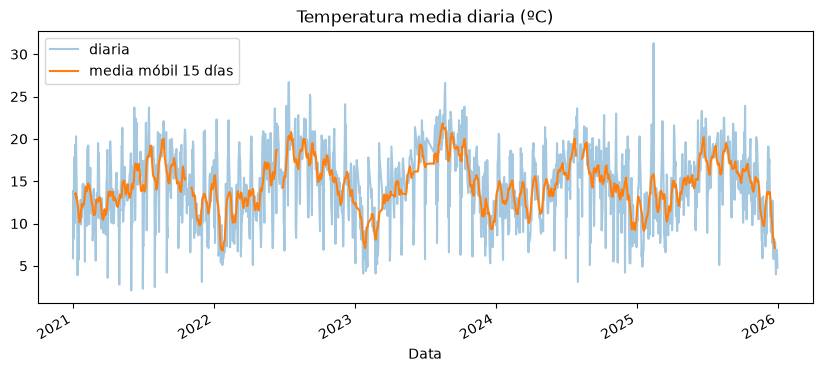

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
tiempo["Temp. media (ºC)"].plot(ax=ax, alpha=0.4, label="diaria")
tiempo["Temp. media (ºC)"].rolling(15, center=True).mean().plot(ax=ax, label="media móbil 15 días")
ax.set_title("Temperatura media diaria (ºC)")
ax.legend()
plt.show()

***5- Limpieza y guardado en datos/clean/***

In [33]:
#Convertir fechas
tiempo["Data"] = pd.to_datetime(tiempo["Data"], format="mixed", dayfirst=True)
tiempo.dtypes
tiempo.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Data                   1812 non-null   datetime64[us]
 1   Temp. media (ºC)       1803 non-null   float64       
 2   Temp. mínima (ºC)      1806 non-null   float64       
 3   Temp. máxima (ºC)      1803 non-null   float64       
 4   Humidade relativa (%)  1812 non-null   int64         
 5   Precipitación (mm)     1804 non-null   str           
 6   Vento medio (km/h)     1812 non-null   float64       
 7   Presión (hPa)          1811 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(1), str(2)
memory usage: 113.4 KB


In [34]:
#Duplicados
tiempo = tiempo.drop_duplicates()

In [35]:
# Interpolar para los valores nulos en las temperaturas
tiempo = tiempo.set_index("Data").sort_index()

for col in ["Temp. media (ºC)", "Temp. mínima (ºC)", "Temp. máxima (ºC)"]:
    tiempo[col] = tiempo[col].interpolate(method="time")

tiempo.isna().sum()


Temp. media (ºC)         0
Temp. mínima (ºC)        0
Temp. máxima (ºC)        0
Humidade relativa (%)    0
Precipitación (mm)       8
Vento medio (km/h)       0
Presión (hPa)            1
dtype: int64

In [36]:
# Limpiar datos imposibles
tiempo.loc[tiempo["Temp. media (ºC)"] < 0, "Temp. media (ºC)"] = pd.NA
tiempo.loc[tiempo["Temp. mínima (ºC)"] < 0, "Temp. mínima (ºC)"] = pd.NA
tiempo.loc[tiempo["Temp. máxima (ºC)"] < 0, "Temp. máxima (ºC)"] = pd.NA
tiempo.describe().round(1)

,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Vento medio (km/h)
count,1801.0,1748.0,1801.0,1804.0,1804.0
mean,14.6,10.6,19.2,80.2,11.9
std,4.3,4.4,4.9,8.1,5.2
min,2.1,0.0,6.7,36.0,3.2
25%,11.4,7.4,15.4,76.0,8.1
50%,14.8,11.0,18.9,81.0,10.4
75%,18.0,14.1,22.8,86.0,14.9
max,31.3,21.1,39.2,100.0,38.5


In [39]:
# Guardar datos limpios en csv
tiempo.to_csv("../datos/clean/meteo_alvedro_2021_2025_limpio.csv", index=False, sep=";", encoding="utf-8")